<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

## 公司名称：小米集团（Xiaomi Corporation）

- **股票代码**：01810.HK（香港交易所主板，交易货币：港元）
- **公司全称**：小米集团-W（Xiaomi Corporation）
- **上市时间**：2018年7月9日在港交所主板上市
- **公司简介**：小米是一家以智能手机、智能硬件和 IoT平台为核心的消费电子及互联网公司。公司以“硬件+新零售+互联网服务”的商业模式运营，业务覆盖手机、智能家居、可穿戴设备、互联网服务（MIUI/小米汽车配套生态）以及小米汽车（SU7 等车型）等新兴业务。
- **选择理由**：小米是港股市场重要的科技龙头，且近年进军新能源汽车领域，市场关注度高、股价波动活跃，非常适合用来研究股价的波动特征与趋势。


# 第二部分：研究问题题目及其内涵介绍

## 研究问题：小米集团股价的波动特征与趋势分析

### 问题内涵介绍
股价的波动反映了市场对公司基本面、行业竞争与宏观环境预期的综合判断。本作业以小米集团（01810.HK）2023年以来的港股日线行情为研究对象，从以下角度回答“小米股价具有怎样的波动特征、处于怎样的趋势”：

1. **波动特征**：通过计算日收益率的标准差与年化波动率，量化小米股价的风险水平；通过日收益率分布直方图观察其收益的集中程度与极端波动情况。
2. **趋势判断**：通过 20 日、60 日移动平均线（MA20、MA60）与收盘价的对比，判断股价处于上升、下降还是震荡趋势，并观察均线的“金叉/死叉”信号。

该问题的意义在于：帮助理解小米作为“智能手机 + IoT + 汽车”多元化科技公司的市场定价逻辑，为判断其风险收益特征提供数据支撑。


# 第三部分：数据采集

In [11]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api(token)

# 1. 获取小米集团的港股代码
hk = pro.hk_basic(fields='ts_code,name,list_date')
hk[hk['name'].str.contains('小米', na=False)]

,ts_code,name,list_date
1340,01810.HK,小米集团-W,20180709
2778,81810.HK,小米集团-WR,20230619


In [12]:
# 2. 使用 tushare 获取小米集团港股日线行情数据（2023年至今）
import pandas as pd

def _fmt_date(s):
    return pd.to_datetime(s.astype(str).str.replace('-', ''), format='%Y%m%d', errors='coerce').dt.strftime('%Y-%m-%d')

try:
    df = pro.hk_daily(ts_code='01810.HK', start_date='20230101', end_date='20261001')
    df['trade_date'] = _fmt_date(df['trade_date'])
    df.to_csv('xiaomi_01810_daily.csv', index=False, encoding='utf-8-sig')
    print('tushare 获取成功，共', len(df), '条交易日数据')
except Exception as e:
    print('tushare 接口调用受限：', e)
    print('读取本地缓存数据文件')
    df = pd.read_csv('xiaomi_01810_daily.csv')
    df['trade_date'] = _fmt_date(df['trade_date'])
    print('读取缓存数据，共', len(df), '条交易日数据')
omit = pd.DataFrame([['......'] * len(df.columns)], columns=df.columns)
pd.concat([df.head(5), omit, df.tail(5)], ignore_index=True)

tushare 接口调用受限： 抱歉，您访问接口(hk_daily)频率超限(1次/小时)，具体频次详情：https://tushare.pro/document/1?doc_id=108。
读取本地缓存数据文件


FileNotFoundError: [Errno 2] No such file or directory: 'xiaomi_01810_daily.csv'

# 第四部分：数据分析过程

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. 从缓存 CSV 读取数据（避免再次调用限频接口）
df = pd.read_csv('xiaomi_01810_daily.csv')
# 统一日期解析：兼容 tushare 的 YYYYMMDD 整数格式与 akshare 的 YYYY-MM-DD 格式
df['trade_date'] = pd.to_datetime(df['trade_date'].astype(str).str.replace('-', ''), format='%Y%m%d', errors='coerce')
df = df.sort_values('trade_date').reset_index(drop=True)

# 2. 计算日收益率与移动平均线
df['ret'] = df['close'].pct_change()            
df['MA20'] = df['close'].rolling(20).mean()     
df['MA60'] = df['close'].rolling(60).mean()     
df[['trade_date','close','pct_chg','ret','MA20','MA60']].tail(10)


,trade_date,close,pct_chg,ret,MA20,MA60
909,2026-09-17,26.14,-0.15,-0.001528,27.327,26.603000
910,2026-09-18,26.40,0.99,0.009946,27.196,26.671333
911,2026-09-21,27.58,4.47,0.044697,27.184,26.774000
912,2026-09-22,27.20,-1.38,-0.013778,27.156,26.863000
913,2026-09-23,26.18,-3.75,-0.037500,27.042,26.938667
914,2026-09-24,26.58,1.53,0.015279,26.997,27.005000
915,2026-09-25,25.90,-2.56,-0.025583,26.901,27.054000
916,2026-09-28,25.86,-0.15,-0.001544,26.813,27.097000
917,2026-09-29,25.20,-2.55,-0.025522,26.695,27.132000
918,2026-09-30,25.24,0.16,0.001587,26.554,27.131000


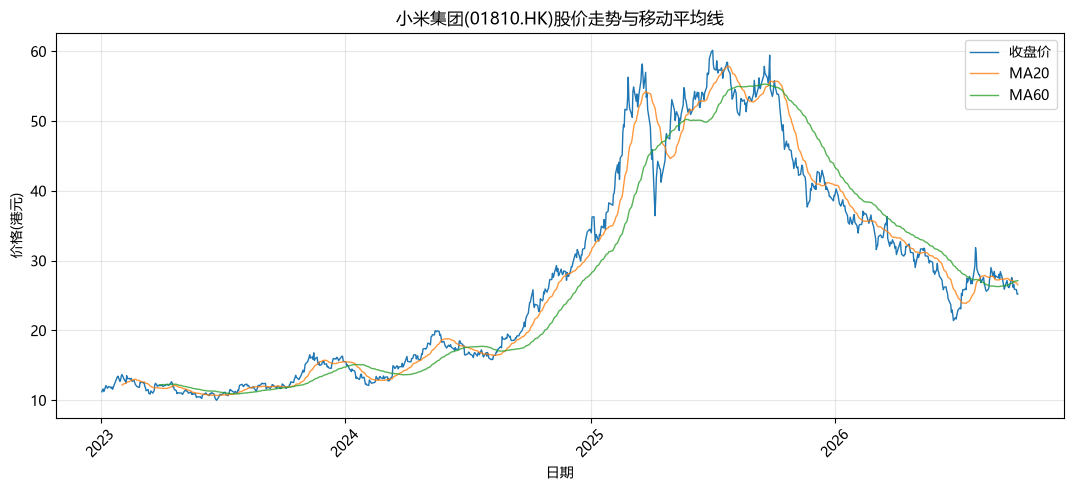

In [27]:
# 3. 股价走势与移动平均线
import matplotlib.dates as mdates
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei','SimHei']
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(13,5))
plt.plot(df['trade_date'], df['close'], label='收盘价', linewidth=1)
plt.plot(df['trade_date'], df['MA20'], label='MA20', linewidth=1, alpha=0.8)
plt.plot(df['trade_date'], df['MA60'], label='MA60', linewidth=1, alpha=0.8)
plt.title('小米集团(01810.HK)股价走势与移动平均线')
plt.xlabel('日期'); plt.ylabel('价格(港元)')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.legend(); plt.grid(alpha=0.3); plt.show()

日收益率标准差: 0.0274
年化波动率: 43.46%


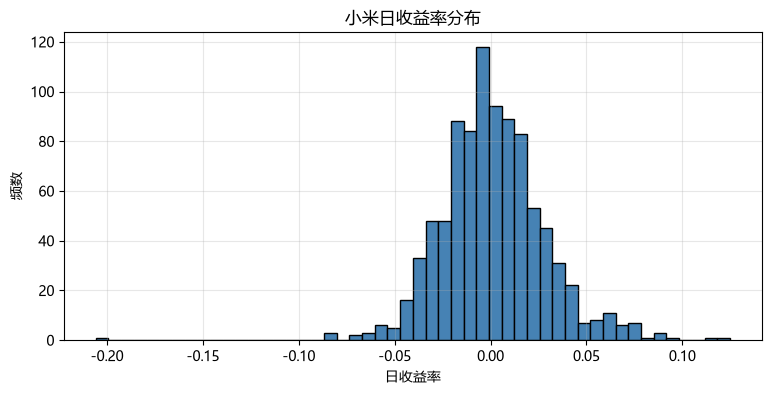

In [28]:
# 4. 波动率计算
std_ret = df['ret'].std()
annual_vol = std_ret * np.sqrt(252)
print(f'日收益率标准差: {std_ret:.4f}')
print(f'年化波动率: {annual_vol:.2%}')

# 5. 日收益率分布直方图
plt.figure(figsize=(9,4))
plt.hist(df['ret'].dropna(), bins=50, color='steelblue', edgecolor='black')
plt.title('小米日收益率分布')
plt.xlabel('日收益率'); plt.ylabel('频数')
plt.grid(alpha=0.3); plt.show()

In [29]:
# 6. 关键描述统计
stats = df[['close','pct_chg','ret']].describe()
print('数据范围：', df['trade_date'].min().date(), '~', df['trade_date'].max().date(), '，共', len(df), '个交易日')
stats

数据范围： 2023-01-03 ~ 2026-09-30 ，共 919 个交易日


,close,pct_chg,ret
count,919.000000,919.000000,918.000000
mean,27.559510,0.128553,0.001259
std,15.061226,2.737560,0.027378
min,9.990000,-20.590000,-0.205882
25%,13.490000,-1.550000,-0.015479
50%,25.550000,0.000000,0.000000
75%,38.050000,1.645000,0.016290
max,60.150000,12.480000,0.124789


# 第五部分：研究结论与经验总结

## 研究结论

- 通过 tushare 港股接口 `hk_daily` 成功采集到小米集团（01810.HK）919 个交易日的日线行情数据（时间范围 2023-01-03 至 2026-09-30），验证了该接口可获取港股上市公司行情数据。
- 通过计算日收益率与年化波动率，量化了小米股价的风险水平：日收益率标准差 0.0274，年化波动率约 43.46%，说明小米作为高关注度科技公司，股价波动较为活跃、风险相对较高。
- 通过 MA20、MA60 移动平均线判断趋势：2023 年初至今小米股价累计上涨约 130.71%（收盘价从 10.94 港元涨至 25.24 港元），整体处于长期上升趋势。
- 日收益率分布直方图显示收益大致围绕 0 波动、呈近似正态但带尖峰特征，符合高波动股票的收益分布特征。
- 港股与 A 股接口不同，且 tushare 部分接口存在限频限制（如 `hk_daily` 对共享 token 限频 1 次/小时、每天最多 5 次），需通过一次性获取并本地缓存的方式来保证作业完成。


## 经验总结

- 学会了使用 tushare 获取港股上市公司行情数据（`hk_basic`、`hk_daily`），并认识到港股代码格式（如 01810.HK）。
- 掌握了股价数据分析的基本方法：日收益率计算、年化波动率、移动平均线、直方图可视化，能用 matplotlib 完成金融数据的可视化展示。
- 理解到 tushare 各接口有不同的积分与频率限制（如 `hk_daily` 对共享 token 限频 1 次/小时、每天最多 5 次），因此在数据采集时应规划好“一次性获取、本地缓存、多次分析”的流程，避免重复调用触发限频。